In [1]:
import sys
sys.path.append("..")
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras # type: ignore
from src.utils import qlike

np.random.seed(42); tf.random.set_seed(42)

df = pd.read_csv("../data/GSPC_processed.csv", index_col=0, parse_dates=True)
r = df["log_return"]

feat = pd.DataFrame({
    "ret": r,
    "sq_ret": r ** 2,
    "abs_mean_5d": r.abs().rolling(5).mean(),
    "rv_21d": df["realized_vol_21d"],
}).dropna()

split = int(len(r) * 0.8)            # same 80/20 split as notebook 03
split_date = r.index[split]
print("Test starts:", split_date.date())

Test starts: 2023-06-06


In [2]:
train_rows = feat.index < split_date
mu, sd = feat[train_rows].mean(), feat[train_rows].std()
feat_s = (feat - mu) / sd

# Target: next-day squared return, divided by its training mean to keep it near 1
y_scale = (r ** 2)[r.index < split_date].mean()
target = (r ** 2).loc[feat.index] / y_scale

In [3]:
LOOK = 22
vals, idx, tgt = feat_s.values, feat_s.index, target.values

X, y, dates = [], [], []
for t in range(LOOK, len(idx)):
    X.append(vals[t - LOOK:t])
    y.append(tgt[t])
    dates.append(idx[t])
X, y, dates = np.array(X), np.array(y), pd.DatetimeIndex(dates)

train_mask = dates < split_date
X_train_all, y_train_all = X[train_mask], y[train_mask]
X_test, y_test, test_dates = X[~train_mask], y[~train_mask], dates[~train_mask]

# Last 10% of training data (chronologically) is held out for early stopping
v = int(len(X_train_all) * 0.9)
X_tr, y_tr = X_train_all[:v], y_train_all[:v]
X_val, y_val = X_train_all[v:], y_train_all[v:]
print(X_tr.shape, X_val.shape, X_test.shape)

(3001, 22, 4) (334, 22, 4) (845, 22, 4)


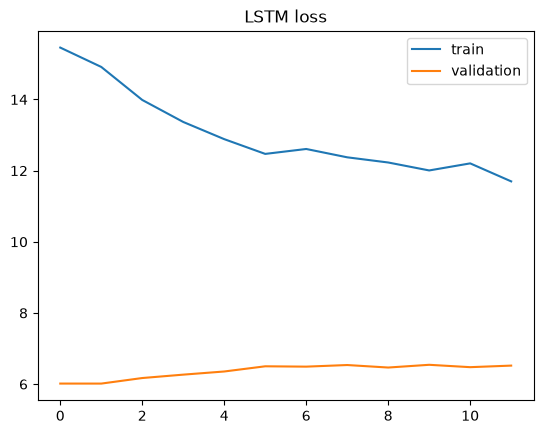

Stopped after 12 epochs


In [4]:
model = keras.Sequential([
    keras.layers.Input(shape=(LOOK, X.shape[2])),
    keras.layers.LSTM(32),
    keras.layers.Dropout(0.2),
    keras.layers.Dense(1, activation="softplus"),
])
model.compile(optimizer=keras.optimizers.Adam(1e-3), loss="mse")

early = keras.callbacks.EarlyStopping(patience=10, restore_best_weights=True)
history = model.fit(X_tr, y_tr, validation_data=(X_val, y_val),
                    epochs=100, batch_size=64, callbacks=[early], verbose=0)

plt.plot(history.history["loss"], label="train")
plt.plot(history.history["val_loss"], label="validation")
plt.title("LSTM loss"); plt.legend(); plt.show()
print("Stopped after", len(history.history["loss"]), "epochs")

In [5]:
pred = model.predict(X_test, verbose=0).ravel() * y_scale
lstm_fc = pd.Series(np.clip(pred, 1e-8, None), index=test_dates, name="LSTM")
lstm_fc.describe()

count    845.000000
mean       0.881871
std        0.660015
min        0.425378
25%        0.587382
50%        0.686755
75%        0.883401
max        5.129014
Name: LSTM, dtype: float64

In [6]:
garch = pd.read_csv("../data/garch_forecasts.csv", index_col=0, parse_dates=True)
all_fc = garch.join(lstm_fc, how="inner").dropna()
proxy = r.loc[all_fc.index] ** 2

rows = {}
for name in all_fc.columns:
    err = all_fc[name] - proxy
    rows[name] = {
        "RMSE": np.sqrt((err ** 2).mean()),
        "MAE": err.abs().mean(),
        "QLIKE": qlike(proxy, all_fc[name]),
    }
final = pd.DataFrame(rows).T.sort_values("QLIKE")
final.round(4)

,RMSE,MAE,QLIKE
GJR-GARCH,3.1085,0.9430,0.5829
EGARCH,3.1395,0.9078,0.5882
LSTM,3.3102,0.9352,0.6028
"GARCH(1,1)",3.3483,1.0071,0.6408
Rolling 21d var,3.4695,1.0043,0.7476


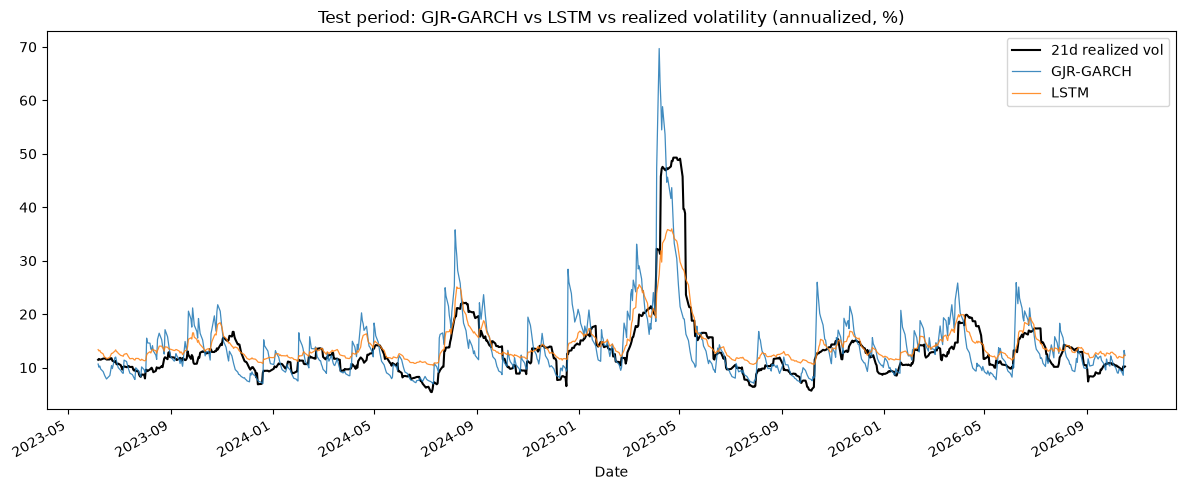

In [7]:
realized = df["realized_vol_21d"].loc[all_fc.index]
fig, ax = plt.subplots(figsize=(12, 5))
realized.plot(ax=ax, color="black", lw=1.5, label="21d realized vol")
for name in ["GJR-GARCH", "LSTM"]:
    np.sqrt(all_fc[name] * 252).plot(ax=ax, lw=0.9, alpha=0.85, label=name)
ax.set_title("Test period: GJR-GARCH vs LSTM vs realized volatility (annualized, %)")
ax.legend(); plt.tight_layout(); plt.show()

In [8]:
lstm_fc.to_csv("../data/lstm_forecasts.csv")